In [1]:
NAMA = 'Wandi'
NIM  = '244107020003'
print('NAMA :', NAMA)
print('NIM  :', NIM)


NAMA : Wandi
NIM  : 244107020003


# Modul 9 - Morfologi

Dilasi dan erosi dibuat manual pakai NumPy, hasilnya dibandingkan dengan OpenCV.
Sisanya (opening, closing, top-hat, black-hat, skeleton) pakai library.


## Persiapan

In [2]:
from google.colab import drive
drive.mount('/content/drive')


Mounted at /content/drive


In [3]:
import cv2 as cv
import numpy as np
from matplotlib import pyplot as plt
import os


In [4]:
CONTOH = '/content/drive/MyDrive/PCVK/Images'
BASE   = CONTOH + '/' + NIM


def muat(kandidat, mode=cv.IMREAD_GRAYSCALE, cadangan=None, nama=''):
    """Coba beberapa path, kembalikan citra pertama yang bisa dibaca."""
    for p in kandidat:
        img = cv.imread(p, mode)
        if img is not None:
            print('dimuat dari :', p)
            return img
    print('TIDAK ADA   :', kandidat)
    if cadangan is not None:
        print('              -> pakai cadangan', nama)
    return cadangan


def kecilkan(img, sisi=420):
    """Perkecil supaya perulangan manual tidak lambat."""
    h, w = img.shape[:2]
    skala = sisi / max(h, w)
    if skala >= 1:
        return img
    return cv.resize(img, None, fx=skala, fy=skala, interpolation=cv.INTER_AREA)


def tampil(ax, img, judul):
    if img.dtype == bool or (img.dtype.kind == 'f' and img.max() <= 1.0):
        ax.imshow(img, cmap='gray')
    else:
        ax.imshow(img, cmap='gray', vmin=0, vmax=255)
    ax.set_title(judul, fontsize=9)
    ax.axis('off')


def grid(citra, judul, ncol=None, skala=4.2):
    ncol = ncol or len(citra)
    nbar = int(np.ceil(len(citra) / ncol))
    fig, axs = plt.subplots(nbar, ncol, figsize=(skala * ncol, skala * nbar))
    for ax, im, t in zip(np.ravel(axs), citra, judul):
        tampil(ax, im, NIM + ' - ' + t)
    for ax in np.ravel(axs)[len(citra):]:
        ax.axis('off')
    plt.tight_layout()
    plt.show()


def plat_buatan(h=150, w=460):
    """Cadangan kalau 'plat nomer.jpg' tidak ada: plat dengan tulisan terang."""
    img = np.full((h, w), 35, np.uint8)
    cv.rectangle(img, (8, 8), (w - 9, h - 9), 200, 2)
    cv.putText(img, 'B 1234 XYZ', (28, 100), cv.FONT_HERSHEY_SIMPLEX, 2.0, 235, 4)
    return img


def j_buatan(h=160, w=160):
    """Cadangan untuk j.png: huruf J putih di latar gelap."""
    img = np.full((h, w), 30, np.uint8)
    cv.putText(img, 'J', (30, 125), cv.FONT_HERSHEY_SIMPLEX, 4.0, 240, 12)
    return img


print('isi folder contoh :', sorted(os.listdir(CONTOH)) if os.path.isdir(CONTOH) else 'belum ada')


isi folder contoh : ['244107020003', 'Lenna.png', 'WhatsApp Image 2026-10-12 at 07.38.31.jpeg', 'djawatan.jpg', 'gradient.jpg', 'lena_gs_lc2.jpg', 'mandrill.tiff', 'sudoku-original.jpg']


## Fungsi manual

Dilasi ambil nilai maksimum di jendela SE, erosi ambil minimum. Piksel di luar batas diisi
0 buat dilasi dan 255 buat erosi, sama seperti OpenCV.


In [5]:
def dilasi(F, SE):
    p, q = F.shape
    kh, kw = SE.shape
    ch, cw = kh // 2, kw // 2
    pad = np.pad(F, ((ch, ch), (cw, cw)), mode='constant', constant_values=0)
    out = np.zeros((p, q), dtype=np.uint8)
    for i in range(p):
        for j in range(q):
            temp = pad[i:i + kh, j:j + kw]
            out[i, j] = np.max(temp[SE == 1])
    return out


def erosi(F, SE):
    m, n = F.shape
    kh, kw = SE.shape
    ch, cw = kh // 2, kw // 2
    pad = np.pad(F, ((ch, ch), (cw, cw)), mode='constant', constant_values=255)
    out = np.zeros((m, n), dtype=np.uint8)
    for i in range(m):
        for j in range(n):
            temp = pad[i:i + kh, j:j + kw]
            out[i, j] = np.min(temp[SE == 1])
    return out


def opening(F, SE):
    return dilasi(erosi(F, SE), SE)


def closing(F, SE):
    return erosi(dilasi(F, SE), SE)


SE_CROSS3 = np.array([[0, 1, 0],
                      [1, 1, 1],
                      [0, 1, 0]], dtype=np.uint8)

SE_CROSS5 = np.array([[0, 0, 1, 0, 0],
                      [0, 0, 1, 0, 0],
                      [1, 1, 1, 1, 1],
                      [0, 0, 1, 0, 0],
                      [0, 0, 1, 0, 0]], dtype=np.uint8)

SE_SQUARE3 = np.ones((3, 3), np.uint8)
SE_SQUARE5 = np.ones((5, 5), np.uint8)

print('SE cross 3x3:\n', SE_CROSS3)


SE cross 3x3:
 [[0 1 0]
 [1 1 1]
 [0 1 0]]


TIDAK ADA   : ['/content/drive/MyDrive/PCVK/Images/plat nomer.jpg', '/content/drive/MyDrive/PCVK/Images/244107020003/plat nomer.jpg', '/content/drive/MyDrive/PCVK/Images/plat_nomer.jpg', '/content/drive/MyDrive/PCVK/Images/244107020003/plat_nomer.jpg']
              -> pakai cadangan plat buatan


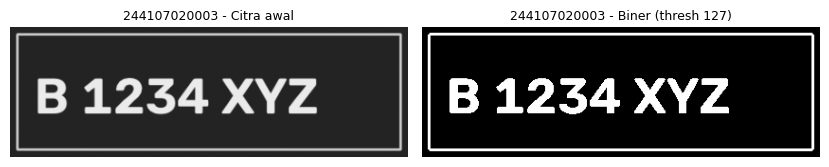

In [6]:
plat = muat([CONTOH + '/plat nomer.jpg', BASE + '/plat nomer.jpg',
             CONTOH + '/plat_nomer.jpg', BASE + '/plat_nomer.jpg'],
            cv.IMREAD_GRAYSCALE, plat_buatan(), 'plat buatan')
plat = kecilkan(plat, 420)

_, bw = cv.threshold(plat, 127, 255, cv.THRESH_BINARY)
grid([plat, bw], ['Citra awal', 'Biner (thresh 127)'])


## 3. Dilasi manual (SE cross 3x3)

Kode contoh di modul pakai `np.ones((w,w))` yang sebenarnya persegi. Saya pakai cross 3x3
sesuai judul tugasnya.


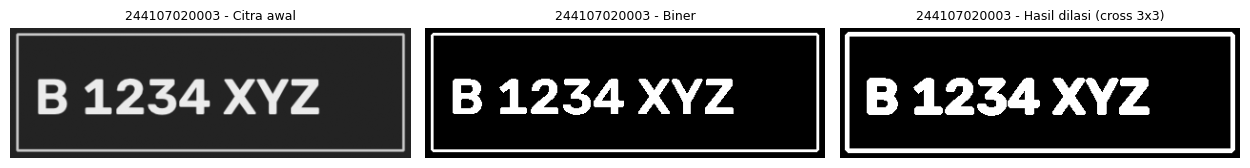

In [7]:
imgD = dilasi(bw, SE_CROSS3)
grid([plat, bw, imgD], ['Citra awal', 'Biner', 'Hasil dilasi (cross 3x3)'])


## 4. Dilasi dengan library OpenCV

[[1 1 1]
 [1 1 1]
 [1 1 1]]


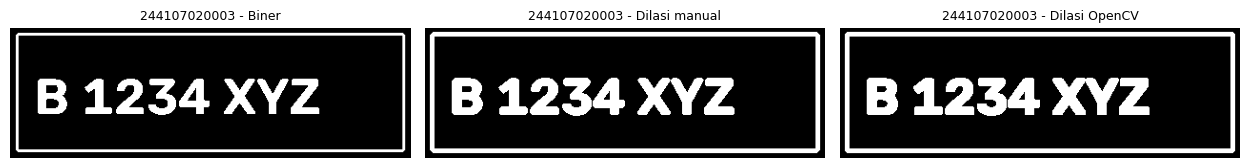

manual vs OpenCV sama? False


In [8]:
kernel = np.ones((3, 3), np.uint16)
dilasi_cv = cv.dilate(bw, kernel, iterations=1)
print(kernel)

grid([bw, imgD, dilasi_cv], ['Biner', 'Dilasi manual', 'Dilasi OpenCV'])
print('manual vs OpenCV sama?', np.array_equal(imgD, dilasi_cv))


## 5. Erosi manual, SE square 5x5

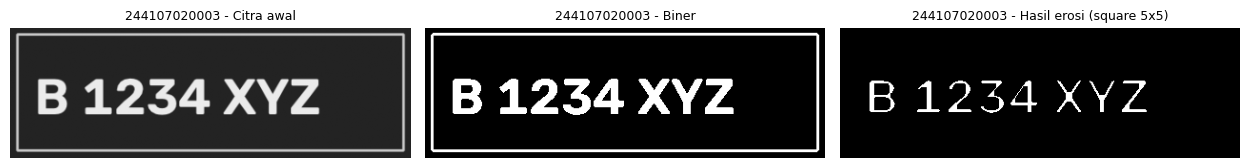

In [9]:
imgE = erosi(bw, SE_SQUARE5)
grid([plat, bw, imgE], ['Citra awal', 'Biner', 'Hasil erosi (square 5x5)'])


## 6. Erosi dengan library OpenCV

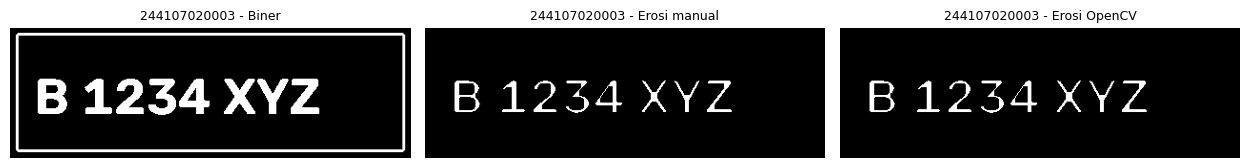

manual vs OpenCV sama? True


In [10]:
kernel = np.ones((5, 5), np.uint8)
erosi_cv = cv.erode(bw, kernel, iterations=1)

grid([bw, imgE, erosi_cv], ['Biner', 'Erosi manual', 'Erosi OpenCV'])
print('manual vs OpenCV sama?', np.array_equal(imgE, erosi_cv))


## 7. Opening (SE square 3x3)

Modul pakai k=7 buat versi manual tapi 3x3 buat versi library. Saya samakan 3x3 di dua-duanya
biar bisa dibandingkan.


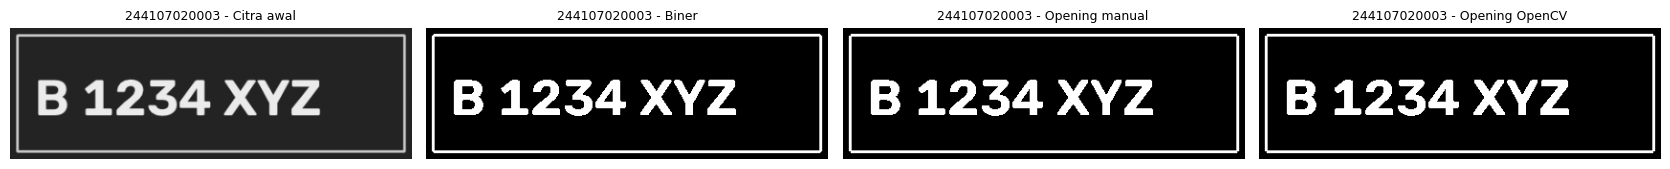

manual vs OpenCV sama? True


In [11]:
imgO = opening(bw, SE_SQUARE3)
open_cv = cv.morphologyEx(bw, cv.MORPH_OPEN, SE_SQUARE3)

grid([plat, bw, imgO, open_cv],
     ['Citra awal', 'Biner', 'Opening manual', 'Opening OpenCV'])
print('manual vs OpenCV sama?', np.array_equal(imgO, open_cv))


## 8. Closing, SE square 3x3

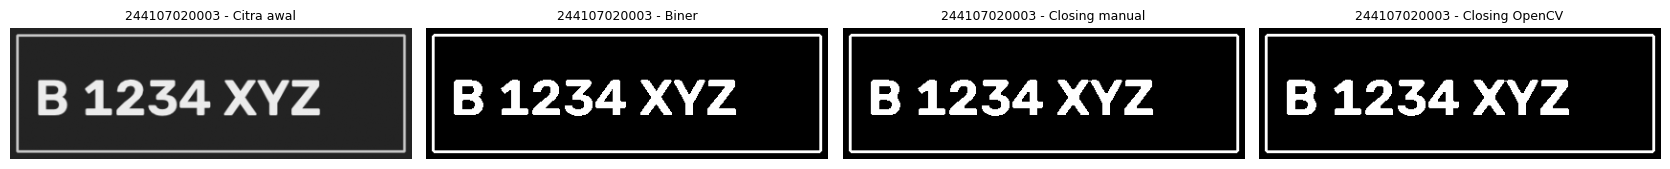

manual vs OpenCV sama? True


In [12]:
imgC = closing(bw, SE_SQUARE3)
close_cv = cv.morphologyEx(bw, cv.MORPH_CLOSE, SE_SQUARE3)

grid([plat, bw, imgC, close_cv],
     ['Citra awal', 'Biner', 'Closing manual', 'Closing OpenCV'])
print('manual vs OpenCV sama?', np.array_equal(imgC, close_cv))


## 9. Dilasi SE cross 3x3 dan 5x5

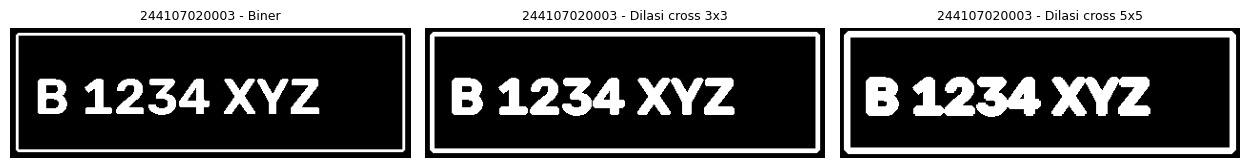

In [13]:
d3 = dilasi(bw, SE_CROSS3)
d5 = dilasi(bw, SE_CROSS5)
grid([bw, d3, d5], ['Biner', 'Dilasi cross 3x3', 'Dilasi cross 5x5'])


## 10. Dilasi SE circular 3x3 dan 5x5

SE circle 5x5:
 [[0 0 1 0 0]
 [1 1 1 1 1]
 [1 1 1 1 1]
 [1 1 1 1 1]
 [0 0 1 0 0]]


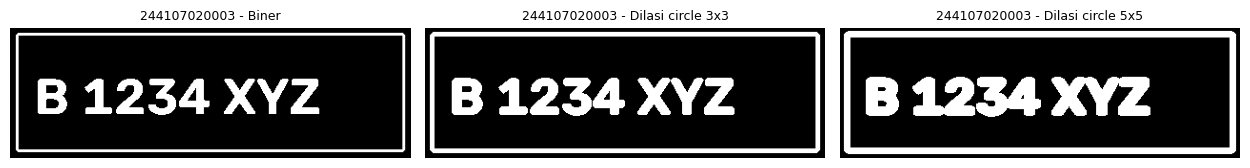

In [14]:
SE_C3 = cv.getStructuringElement(cv.MORPH_ELLIPSE, (3, 3))
SE_C5 = cv.getStructuringElement(cv.MORPH_ELLIPSE, (5, 5))
print('SE circle 5x5:\n', SE_C5)

c3 = dilasi(bw, SE_C3)
c5 = dilasi(bw, SE_C5)
grid([bw, c3, c5], ['Biner', 'Dilasi circle 3x3', 'Dilasi circle 5x5'])


## 11. Erosi SE rectangle 3x5 dan 5x7

SE rect 3x5 (tinggi x lebar):
 [[1 1 1 1 1]
 [1 1 1 1 1]
 [1 1 1 1 1]]


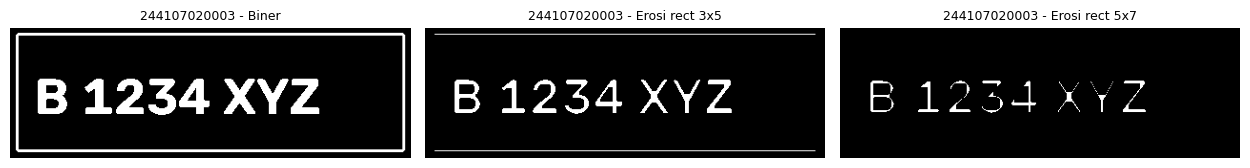

In [15]:
SE_R35 = cv.getStructuringElement(cv.MORPH_RECT, (5, 3))   # lebar 5, tinggi 3
SE_R57 = cv.getStructuringElement(cv.MORPH_RECT, (7, 5))   # lebar 7, tinggi 5
print('SE rect 3x5 (tinggi x lebar):\n', SE_R35)

r35 = erosi(bw, SE_R35)
r57 = erosi(bw, SE_R57)
grid([bw, r35, r57], ['Biner', 'Erosi rect 3x5', 'Erosi rect 5x7'])


## 12. Erosi SE line vertikal 3 dan 5

TIDAK ADA   : ['/content/drive/MyDrive/PCVK/Images/j.png', '/content/drive/MyDrive/PCVK/Images/244107020003/j.png']
              -> pakai cadangan huruf J buatan
SE line vertikal 3:
 [[1]
 [1]
 [1]]


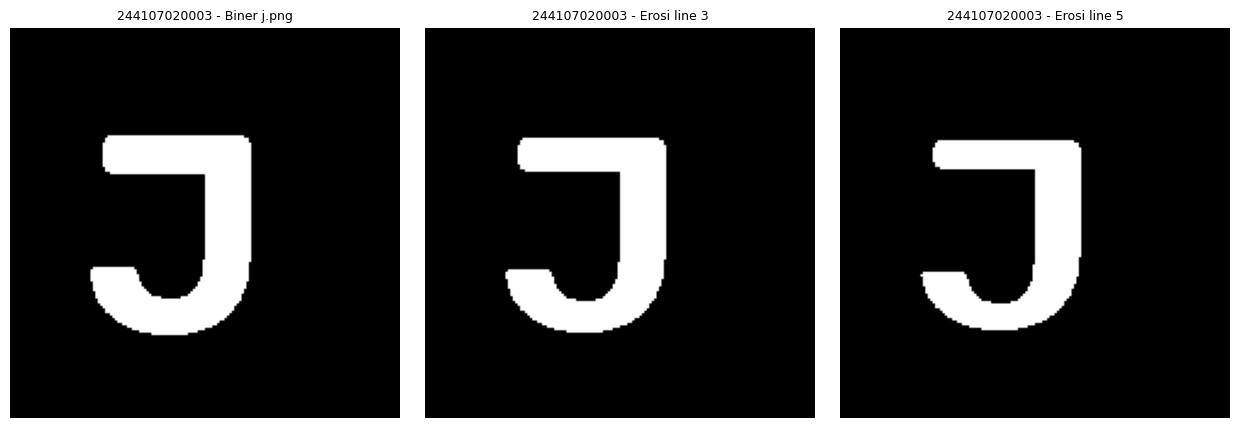

In [16]:
huruf = muat([CONTOH + '/j.png', BASE + '/j.png'],
             cv.IMREAD_GRAYSCALE, j_buatan(), 'huruf J buatan')
huruf = kecilkan(huruf, 300)
_, bw_j = cv.threshold(huruf, 127, 255, cv.THRESH_BINARY)
if bw_j.mean() > 127:            # latar terang -> balik, supaya huruf jadi objek
    bw_j = cv.bitwise_not(bw_j)

SE_L3 = cv.getStructuringElement(cv.MORPH_RECT, (1, 3))    # 3 baris, 1 kolom
SE_L5 = cv.getStructuringElement(cv.MORPH_RECT, (1, 5))
print('SE line vertikal 3:\n', SE_L3)

l3 = erosi(bw_j, SE_L3)
l5 = erosi(bw_j, SE_L5)
grid([bw_j, l3, l5], ['Biner j.png', 'Erosi line 3', 'Erosi line 5'])


## 13. Top-hat

Top-hat = citra asli dikurangi opening. Yang muncul objek terang yang lebih kecil dari SE.


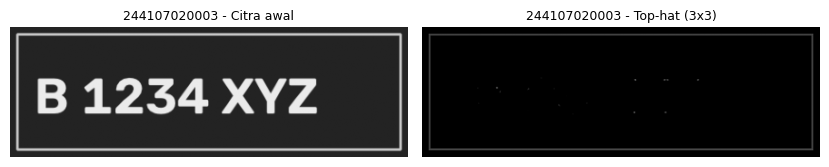

nilai maksimum top-hat : 92


In [17]:
kernel = cv.getStructuringElement(cv.MORPH_RECT, (3, 3))
tophat = cv.morphologyEx(plat, cv.MORPH_TOPHAT, kernel)

grid([plat, tophat], ['Citra awal', 'Top-hat (3x3)'])
print('nilai maksimum top-hat :', int(tophat.max()))


## 14. Black-hat

Black-hat = closing dikurangi citra asli. Yang muncul objek gelap yang lebih kecil dari SE.


TIDAK ADA   : ['/content/drive/MyDrive/PCVK/Images/kitten01.jpg', '/content/drive/MyDrive/PCVK/Images/244107020003/kitten01.jpg']
              -> pakai cadangan skimage.data.chelsea


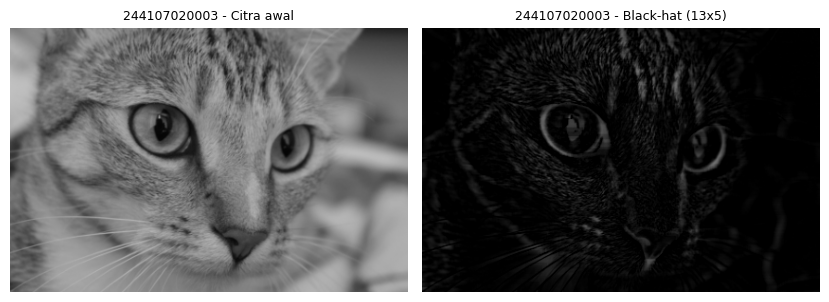

nilai maksimum black-hat : 111


In [18]:
kucing = muat([CONTOH + '/kitten01.jpg', BASE + '/kitten01.jpg'],
               cv.IMREAD_GRAYSCALE, None)
if kucing is None:
    from skimage import data as skdata
    kucing = cv.cvtColor(skdata.chelsea(), cv.COLOR_RGB2GRAY)
    print('              -> pakai cadangan skimage.data.chelsea')
kucing = kecilkan(kucing, 420)

kernel = cv.getStructuringElement(cv.MORPH_RECT, (13, 5))
blackhat = cv.morphologyEx(kucing, cv.MORPH_BLACKHAT, kernel)

grid([kucing, blackhat], ['Citra awal', 'Black-hat (13x5)'])
print('nilai maksimum black-hat :', int(blackhat.max()))


## 15. Skeleton

TIDAK ADA   : ['/content/drive/MyDrive/PCVK/Images/lily.jpg', '/content/drive/MyDrive/PCVK/Images/244107020003/lily.jpg']
              -> pakai cadangan skimage.data.lily


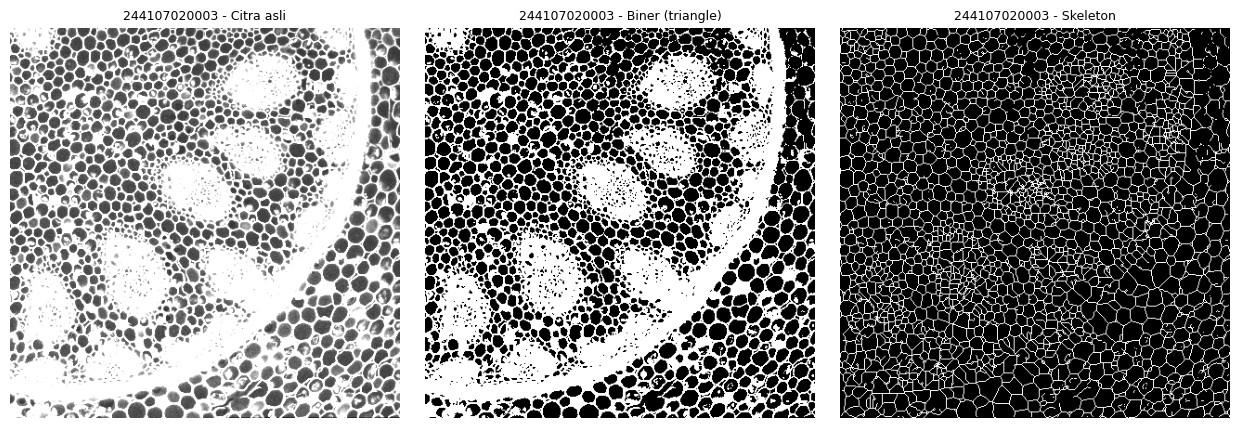

nilai threshold triangle : 256
jumlah piksel skeleton   : 30298


In [19]:
from skimage import filters
from skimage.morphology import skeletonize

lily = muat([CONTOH + '/lily.jpg', BASE + '/lily.jpg'],
            cv.IMREAD_GRAYSCALE, None)
if lily is None:
    from skimage import data as skdata
    lily = cv.cvtColor(skdata.lily(), cv.COLOR_RGB2GRAY)
    print('              -> pakai cadangan skimage.data.lily')
lily = kecilkan(lily, 420)

binary = lily > filters.threshold_triangle(lily)
skeleton = skeletonize(binary)

grid([lily, binary, skeleton], ['Citra asli', 'Biner (triangle)', 'Skeleton'])
print('nilai threshold triangle :', filters.threshold_triangle(lily))
print('jumlah piksel skeleton   :', int(skeleton.sum()))


## 16. Skeleton inverse

Kebalikannya: yang dianggap objek bagian gelap (`<` threshold), jadi skeletonnya mengikuti
garis gelap.


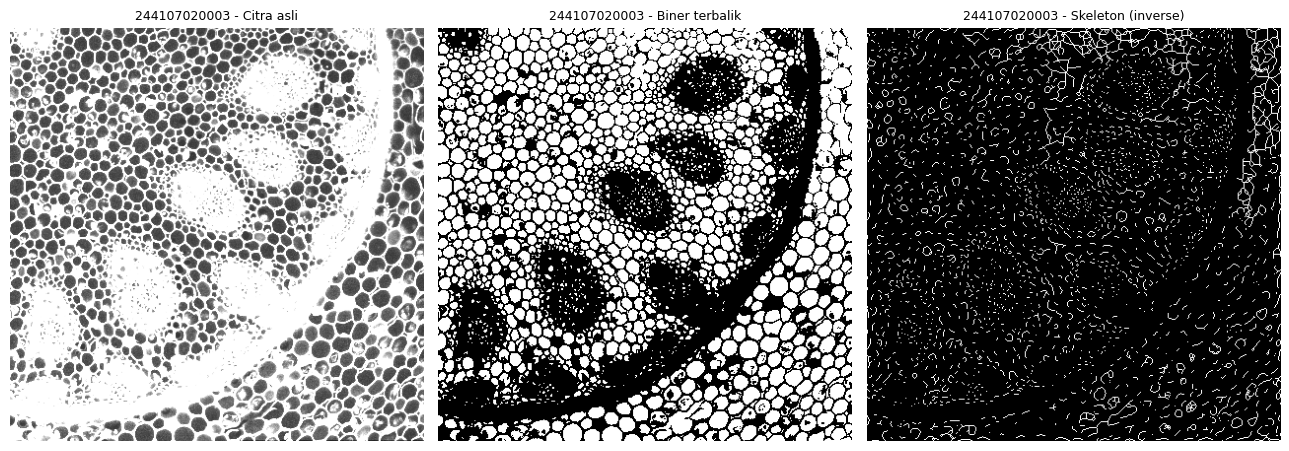

jumlah piksel skeleton inverse : 12080


In [20]:
binary_inv = lily < filters.threshold_triangle(lily)
skeleton_inv = skeletonize(binary_inv)

fig, axs = plt.subplots(1, 3, figsize=(13, 4.5))
tampil(axs[0], lily, NIM + ' - Citra asli')
tampil(axs[1], binary_inv, NIM + ' - Biner terbalik')
tampil(axs[2], skeleton_inv, NIM + ' - Skeleton (inverse)')
plt.tight_layout()
plt.show()

print('jumlah piksel skeleton inverse :', int(skeleton_inv.sum()))


## 17. Thickening

`morphology.thicken` sudah tidak ada di skimage, jadi saya pakai hubungan dualnya:
menebalkan A = menipiskan komplemen A, lalu dibalik lagi.


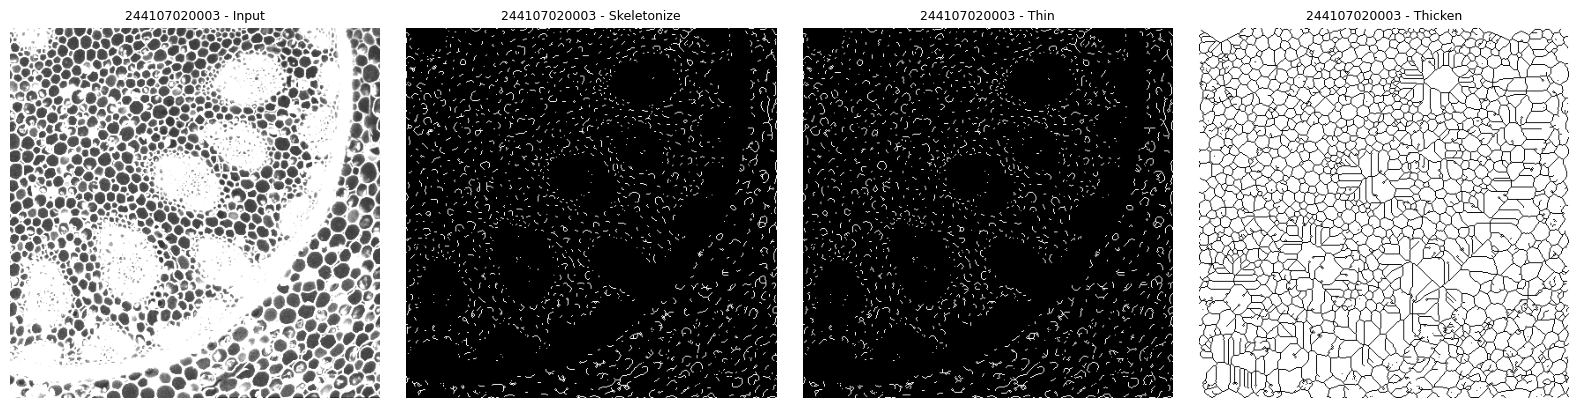

asli         jumlah piksel = 61817
skeletonize  jumlah piksel = 7860
thin         jumlah piksel = 8009
thicken      jumlah piksel = 151519
thin < asli < thicken : True


In [21]:
from skimage import morphology


def thicken(biner):
    """Menebalkan objek: thin pada komplemen, lalu dibalik."""
    return ~morphology.thin(~biner)


gambar_biner = lily < 128
out_skeletonize = morphology.skeletonize(gambar_biner)
out_thin = morphology.thin(gambar_biner)
out_thick = thicken(gambar_biner)

fig, axs = plt.subplots(1, 4, figsize=(16, 4))
tampil(axs[0], lily, NIM + ' - Input')
tampil(axs[1], out_skeletonize, NIM + ' - Skeletonize')
tampil(axs[2], out_thin, NIM + ' - Thin')
tampil(axs[3], out_thick, NIM + ' - Thicken')
plt.tight_layout()
plt.show()

for nama, im in [('asli', gambar_biner), ('skeletonize', out_skeletonize),
                 ('thin', out_thin), ('thicken', out_thick)]:
    print('%-12s jumlah piksel = %d' % (nama, int(im.sum())))
print('thin < asli < thicken :',
      int(out_thin.sum()) < int(gambar_biner.sum()) < int(out_thick.sum()))


## Tugas Praktikum - morfologi pada KTP

Otsu dulu, lalu opening buat buang pola latar yang tipis, closing buat nyambung goresan huruf
yang putus.


dimuat dari : /content/drive/MyDrive/PCVK/Images/244107020003/ktp.jpg


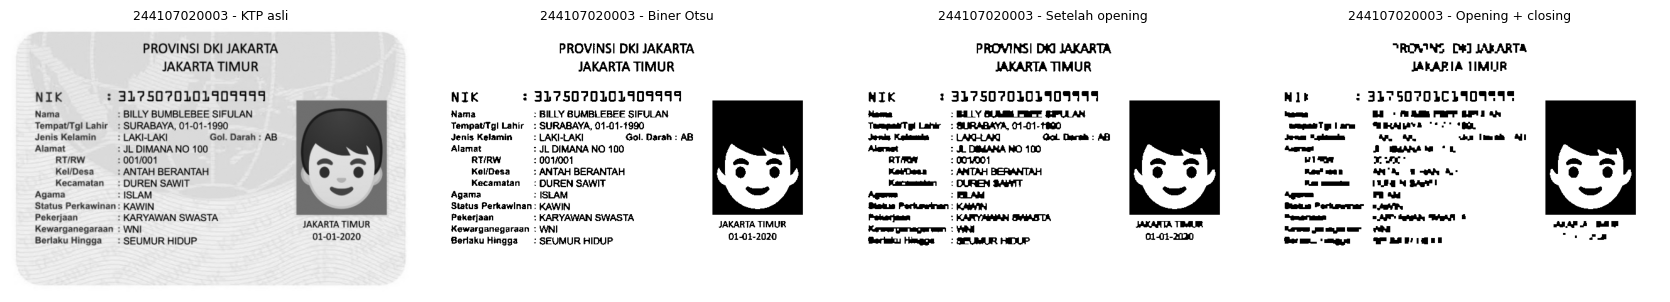

biner Otsu       piksel putih =  233385 (86.41% dari citra)
opening          piksel putih =  229359 (84.92% dari citra)
opening+closing  piksel putih =  233010 (86.27% dari citra)


In [22]:
ktp = muat([BASE + '/ktp.jpg', BASE + '/KTP.jpg', CONTOH + '/ktp_fulan.jpg'],
            cv.IMREAD_GRAYSCALE, None)

if ktp is None:
    print('citra KTP belum ada di', BASE, '- taruh berkas KTP lalu jalankan ulang sel ini.')
else:
    ktp = kecilkan(ktp, 640)

    _, bw_ktp = cv.threshold(ktp, 0, 255, cv.THRESH_BINARY + cv.THRESH_OTSU)

    se = cv.getStructuringElement(cv.MORPH_RECT, (3, 3))
    buka = cv.morphologyEx(bw_ktp, cv.MORPH_OPEN, se)     # buang bintik/pola tipis
    tutup = cv.morphologyEx(buka, cv.MORPH_CLOSE, se)     # sambung huruf terputus
    tutup2 = cv.morphologyEx(tutup, cv.MORPH_CLOSE, se)

    grid([ktp, bw_ktp, buka, tutup2],
         ['KTP asli', 'Biner Otsu', 'Setelah opening', 'Opening + closing'])

    for nama, im in [('biner Otsu', bw_ktp), ('opening', buka), ('opening+closing', tutup2)]:
        jumlah = int((im > 0).sum())
        print('%-16s piksel putih = %7d (%.2f%% dari citra)'
              % (nama, jumlah, 100 * jumlah / im.size))


Opening buang komponen kecil (bintik dan garis latar), closing nutup lubang di dalam huruf.
Kalau hasilnya malah makin tipis, berarti SE-nya kebesaran buat tebal huruf di citra itu.
